# Translation Stage Audit

This notebook is for understanding what happened at each stage of the multilingual translation pipeline run:

- routing into English, native-script, and Roman/Hinglish branches
- detected language mix within each routed branch
- what non-Hindi languages were present
- translated outputs and per-language samples
- low-cosine review slices as a rough quality-control signal
- final merged English output

Default run directory:

- `/scratch/ziv_baretto/Research_X/Partisan-Discourse-on-X-English-/Additional_Steps/Translating/Data/full_multilingual_en_20260403_detached`

In [1]:
from pathlib import Path
import json
import re
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, Markdown, HTML

plt.style.use("seaborn-v0_8-whitegrid")
pd.set_option("display.max_colwidth", None)
pd.set_option("display.max_rows", 200)
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")

BASE_DIR = Path("/scratch/ziv_baretto/Research_X/Partisan-Discourse-on-X-English-/Additional_Steps/Translating")
RUN_DIR = Path("/scratch/ziv_baretto/Research_X/Partisan-Discourse-on-X-English-/Additional_Steps/Translating/Data/full_multilingual_en_20260403_detached")
ROUTED_DIR = RUN_DIR / "routed"
TRANSLATED_DIR = RUN_DIR / "translated"
LOG_DIR = RUN_DIR / "logs"
WORK_DIR = RUN_DIR / "work" / "native_multigpu"

FILES = {
    "routing_summary": ROUTED_DIR / "routing_summary.csv",
    "english_routed": ROUTED_DIR / "english_tweets.csv",
    "native_routed": ROUTED_DIR / "hindi_script_tweets.csv",
    "roman_routed": ROUTED_DIR / "hinglish_roman_tweets.csv",
    "native_translated": TRANSLATED_DIR / "hindi_script_en.csv",
    "roman_translated": TRANSLATED_DIR / "hinglish_roman_en.csv",
    "native_lowcos": TRANSLATED_DIR / "hindi_script_lowcos.csv",
    "roman_lowcos": TRANSLATED_DIR / "hinglish_roman_lowcos.csv",
    "merged": RUN_DIR / "retweet_data_combined_labeled_by_retweet_en.csv",
    "manifest": WORK_DIR / "manifest.json",
    "route_log": LOG_DIR / "01_route.log",
    "native_log": LOG_DIR / "02_translate_native.log",
    "roman_log": LOG_DIR / "03_translate_roman.log",
    "assemble_log": LOG_DIR / "06_assemble_native_multigpu.log",
    "merge_log": LOG_DIR / "07_merge_after_multigpu.log",
}

display(
    HTML(
        '''
        <style>
        table.dataframe td, table.dataframe th {
            white-space: pre-wrap !important;
            max-width: none !important;
            overflow: visible !important;
            text-overflow: clip !important;
            vertical-align: top !important;
        }
        </style>
        '''
    )
)

In [2]:
ROW_COUNT_CACHE = {}


def count_csv_rows(path: Path, chunksize: int = 200_000) -> int | None:
    if not path.exists():
        return None
    key = str(path.resolve())
    if key in ROW_COUNT_CACHE:
        return ROW_COUNT_CACHE[key]
    total = 0
    for chunk in pd.read_csv(path, usecols=["row_id"], chunksize=chunksize):
        total += len(chunk)
    ROW_COUNT_CACHE[key] = total
    return total


def file_inventory() -> pd.DataFrame:
    rows = []
    for name, path in FILES.items():
        rows.append(
            {
                "name": name,
                "path": str(path),
                "exists": path.exists(),
                "size_mb": round(path.stat().st_size / (1024 * 1024), 2) if path.exists() else None,
            }
        )
    return pd.DataFrame(rows).sort_values(["exists", "name"], ascending=[False, True]).reset_index(drop=True)


def load_routing_summary() -> pd.DataFrame:
    df = pd.read_csv(FILES["routing_summary"])
    df["count"] = df["count"].astype(int)
    return df


def route_counts_table() -> pd.DataFrame:
    df = load_routing_summary()
    out = df[df["level"] == "route"][["route", "count"]].copy()
    total = out["count"].sum()
    out["pct_total"] = out["count"] / total
    return out.sort_values("count", ascending=False).reset_index(drop=True)


def language_counts(route: str) -> pd.DataFrame:
    df = load_routing_summary()
    route_total = int(df[(df["level"] == "route") & (df["route"] == route)]["count"].iloc[0])
    out = df[(df["level"] == "route_lang") & (df["route"] == route)][["lid_lang", "count"]].copy()
    out["pct_branch"] = out["count"] / route_total
    out["route"] = route
    return out.sort_values("count", ascending=False).reset_index(drop=True)


def count_values(path: Path, col: str, chunksize: int = 200_000) -> pd.Series:
    counts = None
    for chunk in pd.read_csv(path, usecols=[col], chunksize=chunksize):
        vc = chunk[col].fillna("NA").astype(str).value_counts()
        counts = vc if counts is None else counts.add(vc, fill_value=0)
    if counts is None:
        return pd.Series(dtype="int64")
    return counts.sort_values(ascending=False).astype(int)


def sample_rows(path: Path, mask_fn, columns=None, n: int = 5, chunksize: int = 100_000, random_state: int = 42) -> pd.DataFrame:
    if not path.exists():
        return pd.DataFrame(columns=columns)
    rng = np.random.default_rng(random_state)
    keep = []
    for chunk in pd.read_csv(path, chunksize=chunksize, usecols=columns):
        hit = chunk[mask_fn(chunk)]
        if hit.empty:
            continue
        take = min(len(hit), max(1, n))
        keep.append(hit.sample(n=take, random_state=int(rng.integers(0, 1_000_000_000))))
    if not keep:
        return pd.DataFrame(columns=columns)
    out = pd.concat(keep, ignore_index=True)
    if len(out) > n:
        out = out.sample(n=n, random_state=random_state)
    return out.reset_index(drop=True)


def sample_language(path: Path, lid_lang: str, columns=None, n: int = 3, chunksize: int = 100_000) -> pd.DataFrame:
    return sample_rows(path, lambda df: df["lid_lang"].fillna("") == lid_lang, columns=columns, n=n, chunksize=chunksize)


def sample_top_languages(path: Path, langs: list[str], columns=None, n_per_lang: int = 2) -> pd.DataFrame:
    frames = []
    for idx, lang in enumerate(langs):
        df = sample_language(path, lang, columns=columns, n=n_per_lang, chunksize=100_000)
        if not df.empty:
            frames.append(df)
    if not frames:
        return pd.DataFrame(columns=columns)
    return pd.concat(frames, ignore_index=True)


def cosine_language_stats(path: Path, min_count: int = 500, chunksize: int = 200_000) -> pd.DataFrame:
    sums = {}
    counts = {}
    for chunk in pd.read_csv(path, usecols=["lid_lang", "cosine_before_after"], chunksize=chunksize):
        grp = chunk.groupby("lid_lang")["cosine_before_after"].agg(["sum", "count"])
        for lang, row in grp.iterrows():
            sums[lang] = sums.get(lang, 0.0) + float(row["sum"])
            counts[lang] = counts.get(lang, 0) + int(row["count"])
    rows = []
    for lang, count in counts.items():
        if count < min_count:
            continue
        rows.append(
            {
                "lid_lang": lang,
                "count": count,
                "avg_cosine": sums[lang] / count,
            }
        )
    return pd.DataFrame(rows).sort_values(["count", "avg_cosine"], ascending=[False, False]).reset_index(drop=True)


def lowcos_rate_table(route: str, lowcos_path: Path) -> pd.DataFrame:
    totals = language_counts(route)[["lid_lang", "count"]].rename(columns={"count": "total_rows"})
    low = count_values(lowcos_path, "lid_lang").rename("lowcos_rows").reset_index().rename(columns={"index": "lid_lang"})
    out = totals.merge(low, on="lid_lang", how="left")
    out["lowcos_rows"] = out["lowcos_rows"].fillna(0).astype(int)
    out["lowcos_rate"] = out["lowcos_rows"] / out["total_rows"]
    return out.sort_values(["lowcos_rate", "total_rows"], ascending=[False, False]).reset_index(drop=True)


def lookup_row(row_id: int) -> dict:
    targets = {
        "english_routed": FILES["english_routed"],
        "native_routed": FILES["native_routed"],
        "roman_routed": FILES["roman_routed"],
        "native_translated": FILES["native_translated"],
        "roman_translated": FILES["roman_translated"],
        "merged": FILES["merged"],
    }
    found = {}
    for name, path in targets.items():
        if not path.exists():
            continue
        hits = []
        for chunk in pd.read_csv(path, chunksize=100_000):
            match = chunk[chunk["row_id"] == row_id]
            if not match.empty:
                hits.append(match)
        if hits:
            found[name] = pd.concat(hits, ignore_index=True)
    return found

## File Inventory

These are the main stage outputs, logs, and run artifacts available inside the run directory.

In [3]:
display(file_inventory())

,name,path,exists,size_mb
0,assemble_log,/scratch/ziv_baretto/Research_X/Partisan-Discourse-on-X-English-/Additional_Steps/Translating/Data/full_multilingual_en_20260403_detached/logs/06_assemble_native_multigpu.log,True,0.0000
1,english_routed,/scratch/ziv_baretto/Research_X/Partisan-Discourse-on-X-English-/Additional_Steps/Translating/Data/full_multilingual_en_20260403_detached/routed/english_tweets.csv,True,"1,464.4000"
2,manifest,/scratch/ziv_baretto/Research_X/Partisan-Discourse-on-X-English-/Additional_Steps/Translating/Data/full_multilingual_en_20260403_detached/work/native_multigpu/manifest.json,True,0.0000
3,merge_log,/scratch/ziv_baretto/Research_X/Partisan-Discourse-on-X-English-/Additional_Steps/Translating/Data/full_multilingual_en_20260403_detached/logs/07_merge_after_multigpu.log,True,0.0000
4,merged,/scratch/ziv_baretto/Research_X/Partisan-Discourse-on-X-English-/Additional_Steps/Translating/Data/full_multilingual_en_20260403_detached/retweet_data_combined_labeled_by_retweet_en.csv,True,"6,525.7500"
5,native_log,/scratch/ziv_baretto/Research_X/Partisan-Discourse-on-X-English-/Additional_Steps/Translating/Data/full_multilingual_en_20260403_detached/logs/02_translate_native.log,True,0.9200
6,native_lowcos,/scratch/ziv_baretto/Research_X/Partisan-Discourse-on-X-English-/Additional_Steps/Translating/Data/full_multilingual_en_20260403_detached/translated/hindi_script_lowcos.csv,True,421.6400
7,native_routed,/scratch/ziv_baretto/Research_X/Partisan-Discourse-on-X-English-/Additional_Steps/Translating/Data/full_multilingual_en_20260403_detached/routed/hindi_script_tweets.csv,True,"3,652.9600"
8,native_translated,/scratch/ziv_baretto/Research_X/Partisan-Discourse-on-X-English-/Additional_Steps/Translating/Data/full_multilingual_en_20260403_detached/translated/hindi_script_en.csv,True,"4,462.7800"
9,roman_log,/scratch/ziv_baretto/Research_X/Partisan-Discourse-on-X-English-/Additional_Steps/Translating/Data/full_multilingual_en_20260403_detached/logs/03_translate_roman.log,True,0.0300


## Stage Summary

This section summarizes the route split, translated output sizes, low-cosine review slices, and the 4-GPU native resume details.

In [4]:
route_counts = route_counts_table()
native_rows = count_csv_rows(FILES["native_translated"])
roman_rows = count_csv_rows(FILES["roman_translated"])
native_lowcos_rows = count_csv_rows(FILES["native_lowcos"])
roman_lowcos_rows = count_csv_rows(FILES["roman_lowcos"])
merged_rows = count_csv_rows(FILES["merged"])

stages = pd.DataFrame(
    [
        {"stage": "english_routed", "rows": int(route_counts.loc[route_counts["route"] == "english", "count"].iloc[0])},
        {"stage": "native_routed", "rows": int(route_counts.loc[route_counts["route"] == "hindi_script", "count"].iloc[0])},
        {"stage": "roman_routed", "rows": int(route_counts.loc[route_counts["route"] == "hinglish_roman", "count"].iloc[0])},
        {"stage": "native_translated", "rows": native_rows},
        {"stage": "roman_translated", "rows": roman_rows},
        {"stage": "native_lowcos_review", "rows": native_lowcos_rows},
        {"stage": "roman_lowcos_review", "rows": roman_lowcos_rows},
        {"stage": "merged_final", "rows": merged_rows},
    ]
)
total_rows = int(route_counts["count"].sum())
stages["pct_of_total"] = stages["rows"] / total_rows
display(stages)

manifest = json.loads(FILES["manifest"].read_text()) if FILES["manifest"].exists() else None
if manifest:
    shard_df = pd.DataFrame(manifest["shard_inputs"])
    shard_df["path"] = shard_df["path"].astype(str)
    shard_df["shard_name"] = shard_df["path"].str.extract(r"(part_\d+\.csv)")
    shard_df = shard_df[["shard_name", "rows", "path"]]
    display(
        pd.DataFrame(
            [
                {"metric": "native_total_rows", "value": manifest["native_total_rows"]},
                {"metric": "prefix_rows_completed_before_4gpu_resume", "value": manifest["prefix_rows"]},
                {"metric": "remaining_rows_sent_to_4gpu_resume", "value": manifest["remaining_rows"]},
                {"metric": "num_shards", "value": len(manifest["shard_inputs"])},
            ]
        )
    )
    display(shard_df)

,stage,rows,pct_of_total
0,english_routed,3006222,0.4225
1,native_routed,4078560,0.5732
2,roman_routed,31181,0.0044
3,native_translated,4078560,0.5732
4,roman_translated,31181,0.0044
5,native_lowcos_review,407856,0.0573
6,roman_lowcos_review,3118,0.0004
7,merged_final,7115963,1.0000


,metric,value
0,native_total_rows,4078560
1,prefix_rows_completed_before_4gpu_resume,2560000
2,remaining_rows_sent_to_4gpu_resume,1518560
3,num_shards,4


,shard_name,rows,path
0,part_00.csv,379640,/scratch/ziv_baretto/Research_X/Partisan-Discourse-on-X-English-/Additional_Steps/Translating/Data/full_multilingual_en_20260403_detached/work/native_multigpu/inputs/part_00.csv
1,part_01.csv,379640,/scratch/ziv_baretto/Research_X/Partisan-Discourse-on-X-English-/Additional_Steps/Translating/Data/full_multilingual_en_20260403_detached/work/native_multigpu/inputs/part_01.csv
2,part_02.csv,379640,/scratch/ziv_baretto/Research_X/Partisan-Discourse-on-X-English-/Additional_Steps/Translating/Data/full_multilingual_en_20260403_detached/work/native_multigpu/inputs/part_02.csv
3,part_03.csv,379640,/scratch/ziv_baretto/Research_X/Partisan-Discourse-on-X-English-/Additional_Steps/Translating/Data/full_multilingual_en_20260403_detached/work/native_multigpu/inputs/part_03.csv


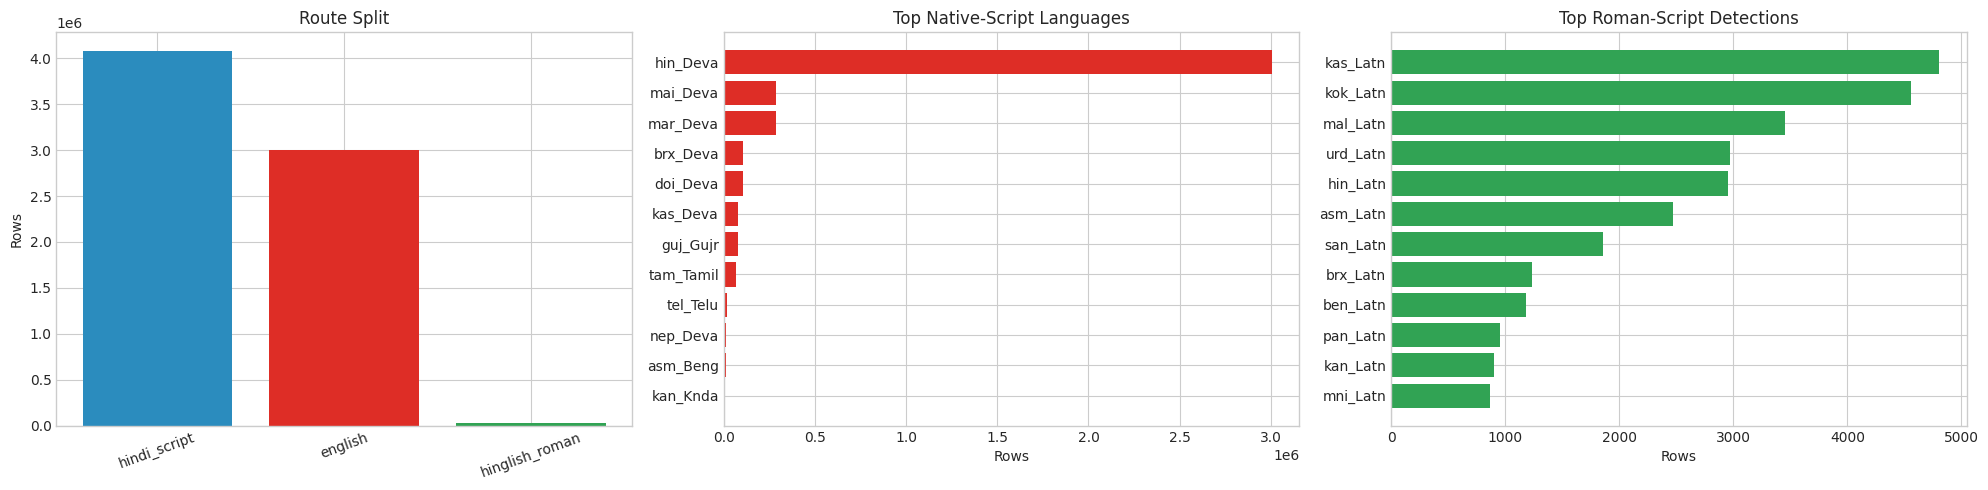

In [5]:
native_langs = language_counts("hindi_script")
roman_langs = language_counts("hinglish_roman")
english_langs = language_counts("english")

fig, axes = plt.subplots(1, 3, figsize=(20, 5))

axes[0].bar(route_counts["route"], route_counts["count"], color=["#2b8cbe", "#de2d26", "#31a354"])
axes[0].set_title("Route Split")
axes[0].set_ylabel("Rows")
axes[0].tick_params(axis="x", rotation=20)

native_top = native_langs.head(12).sort_values("count")
axes[1].barh(native_top["lid_lang"], native_top["count"], color="#de2d26")
axes[1].set_title("Top Native-Script Languages")
axes[1].set_xlabel("Rows")

roman_top = roman_langs.head(12).sort_values("count")
axes[2].barh(roman_top["lid_lang"], roman_top["count"], color="#31a354")
axes[2].set_title("Top Roman-Script Detections")
axes[2].set_xlabel("Rows")

plt.tight_layout()
plt.show()

## Are There Languages Other Than Hindi?

Yes. This section quantifies them directly from the routing summary.

In [6]:
native_hindi = int(native_langs.loc[native_langs["lid_lang"] == "hin_Deva", "count"].iloc[0])
native_other = int(native_langs.loc[native_langs["lid_lang"] != "hin_Deva", "count"].sum())
roman_hindi = int(roman_langs.loc[roman_langs["lid_lang"] == "hin_Latn", "count"].iloc[0])
roman_other = int(roman_langs.loc[roman_langs["lid_lang"] != "hin_Latn", "count"].sum())
english_other = int(english_langs.loc[english_langs["lid_lang"] == "other", "count"].iloc[0])

non_hindi_summary = pd.DataFrame(
    [
        {"branch": "native_script", "hindi_rows": native_hindi, "non_hindi_rows": native_other, "non_hindi_pct": native_other / (native_hindi + native_other)},
        {"branch": "roman_hinglish", "hindi_rows": roman_hindi, "non_hindi_rows": roman_other, "non_hindi_pct": roman_other / (roman_hindi + roman_other)},
        {"branch": "english_passthrough", "hindi_rows": None, "non_hindi_rows": english_other, "non_hindi_pct": english_other / int(english_langs["count"].sum())},
    ]
)
display(non_hindi_summary)

display(Markdown("### Top non-Hindi native-script languages"))
display(native_langs.query("lid_lang != 'hin_Deva'").head(15))

display(Markdown("### Top non-Hindi Roman-script detections"))
display(roman_langs.query("lid_lang != 'hin_Latn'").head(15))

,branch,hindi_rows,non_hindi_rows,non_hindi_pct
0,native_script,"3,005,825.0000",1072735,0.2630
1,roman_hinglish,"2,954.0000",28227,0.9053
2,english_passthrough,NaN,138676,0.0461


### Top non-Hindi native-script languages

,lid_lang,count,pct_branch,route
1,mai_Deva,288015,0.0706,hindi_script
2,mar_Deva,285182,0.0699,hindi_script
3,brx_Deva,106101,0.0260,hindi_script
4,doi_Deva,104304,0.0256,hindi_script
5,kas_Deva,79085,0.0194,hindi_script
6,guj_Gujr,76015,0.0186,hindi_script
7,tam_Tamil,65605,0.0161,hindi_script
8,tel_Telu,16221,0.0040,hindi_script
9,nep_Deva,12572,0.0031,hindi_script
10,asm_Beng,11399,0.0028,hindi_script


### Top non-Hindi Roman-script detections

,lid_lang,count,pct_branch,route
0,kas_Latn,4806,0.1541,hinglish_roman
1,kok_Latn,4555,0.1461,hinglish_roman
2,mal_Latn,3452,0.1107,hinglish_roman
3,urd_Latn,2967,0.0952,hinglish_roman
5,asm_Latn,2468,0.0792,hinglish_roman
6,san_Latn,1859,0.0596,hinglish_roman
7,brx_Latn,1232,0.0395,hinglish_roman
8,ben_Latn,1181,0.0379,hinglish_roman
9,pan_Latn,954,0.0306,hinglish_roman
10,kan_Latn,906,0.0291,hinglish_roman


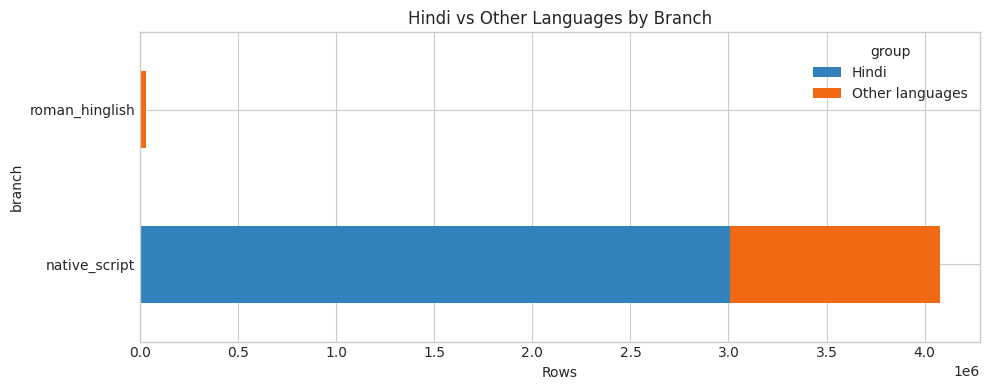

In [7]:
mix_df = pd.DataFrame(
    [
        {"branch": "native_script", "group": "Hindi", "rows": native_hindi},
        {"branch": "native_script", "group": "Other languages", "rows": native_other},
        {"branch": "roman_hinglish", "group": "Hindi", "rows": roman_hindi},
        {"branch": "roman_hinglish", "group": "Other languages", "rows": roman_other},
    ]
)
mix_pivot = mix_df.pivot(index="branch", columns="group", values="rows")

ax = mix_pivot.plot(kind="barh", stacked=True, figsize=(10, 4), color=["#3182bd", "#f16913"])
ax.set_title("Hindi vs Other Languages by Branch")
ax.set_xlabel("Rows")
plt.tight_layout()
plt.show()

## Sample Outputs By Language

These samples show routed or translated rows for non-Hindi detections so you can see what those labels actually look like in the data.

In [8]:
english_other_cols = ["row_id", "lid_lang", "tweet_original", "tweet", "translation_route"]
translated_cols = ["row_id", "lid_lang", "nllb_src_lang", "tweet_original", "tweet", "en_text", "cosine_before_after"]

display(Markdown("### English branch rows labeled as `other`"))
display(sample_rows(FILES["english_routed"], lambda df: df["lid_lang"].fillna("") == "other", columns=english_other_cols, n=8))

top_native_non_hindi = native_langs.query("lid_lang != 'hin_Deva'").head(8)["lid_lang"].tolist()
display(Markdown("### Native-script translated samples for top non-Hindi languages"))
for lang in top_native_non_hindi:
    display(Markdown(f"#### {lang}"))
    display(sample_language(FILES["native_translated"], lang, columns=translated_cols, n=3))

top_roman_langs = roman_langs.head(8)["lid_lang"].tolist()
display(Markdown("### Roman/Hinglish translated samples for top detected languages"))
for lang in top_roman_langs:
    display(Markdown(f"#### {lang}"))
    display(sample_language(FILES["roman_translated"], lang, columns=translated_cols, n=3))

### English branch rows labeled as `other`

,tweet,row_id,tweet_original,translation_route,lid_lang
0,"And much,much needed HOPE! 🙏🙏🙏 https://t.co/0IKkMbo7Os",1005762,"And much,much needed HOPE! 🙏🙏🙏 https://t.co/0IKkMbo7Os",english,other
1,Posting without my comment.... https://t.co/5DURzRR54f,74752,Posting without my comment.... https://t.co/5DURzRR54f,english,other
2,Wish you a very #HappyNewYear \n#HAPPYNEWYEAR2022 \n#NewYear2022 https://t.co/TjSBLUmwPZ,5045733,Wish you a very #HappyNewYear \n#HAPPYNEWYEAR2022 \n#NewYear2022 https://t.co/TjSBLUmwPZ,english,other
3,Watch LIVE https://t.co/Gfzmj3Wc7l,2349942,Watch LIVE https://t.co/Gfzmj3Wc7l,english,other
4,All the cheerleading we need❤️\n\n#BharatJodoYatra 🇮🇳 https://t.co/TOR1DXuOwY,4284860,All the cheerleading we need❤️\n\n#BharatJodoYatra 🇮🇳 https://t.co/TOR1DXuOwY,english,other
5,Chanakya Painting in Parliament.🔥 https://t.co/aNS8QNmNuT,7110010,Chanakya Painting in Parliament.🔥 https://t.co/aNS8QNmNuT,english,other
6,https://t.co/u05P8WtvwU,5585659,https://t.co/u05P8WtvwU,english,other
7,https://t.co/AElcHEOppF,3001874,https://t.co/AElcHEOppF,english,other


### Native-script translated samples for top non-Hindi languages

#### mai_Deva

,tweet,row_id,tweet_original,lid_lang,nllb_src_lang,en_text,cosine_before_after
0,दान करना है तो गुरुद्वारे में करो\n\nकोई भूखा नहीं सोएगा 🙏🏼,1181018,दान करना है तो गुरुद्वारे में करो\n\nकोई भूखा नहीं सोएगा 🙏🏼,mai_Deva,mai_Deva,"If you want to donate, do it in Gurudwara. No one will sleep hungry.",0.7657
1,इनको भी फ़ॉलो करो : @patrafrzi \n\nजो RT करे और फ़ॉलो ना दे उसको ब्लॉक करते जाओ 🙏,2840894,इनको भी फ़ॉलो करो : @patrafrzi \n\nजो RT करे और फ़ॉलो ना दे उसको ब्लॉक करते जाओ 🙏,mai_Deva,mai_Deva,Follow them too: @patrafrzi block what RT does and doesn't follow 🙏,0.8023
2,GoodNight ट्विटर डिलीट कर रहा हूँ \n\nकोई मेरा दोस्त नही बनता कोई मुझे फ़ॉलो नही करता \n\nमैं नया हूँ कोई मेरा साथ नही देता,2946409,GoodNight ट्विटर डिलीट कर रहा हूँ \n\nकोई मेरा दोस्त नही बनता कोई मुझे फ़ॉलो नही करता \n\nमैं नया हूँ कोई मेरा साथ नही देता,mai_Deva,mai_Deva,I'm deleting Twitter. No one is my friend. No one follows me. I'm new. No one is my follower.,0.8588


#### mar_Deva

... (26 outputs left out)

#### san_Latn

,tweet,row_id,tweet_original,lid_lang,nllb_src_lang,en_text,cosine_before_after
0,@TheRightster @AdvAshutoshDube @ModifiedAayush @Aniiiiish @Yadu_Kula @vijaygajera @Aniiiiish @memenist_ @Eroceanic @kannadaveera @Keshu__10 @AbhiBalasara @TheShobhitAzad @earfrekgabru,3985770,@TheRightster @AdvAshutoshDube @ModifiedAayush @Aniiiiish @Yadu_Kula @vijaygajera @Aniiiiish @memenist_ @Eroceanic @kannadaveera @Keshu__10 \n@AbhiBalasara @TheShobhitAzad \n@earfrekgabru,san_Latn,hin_Deva,@TheRightster @AdvAshutoshDube @ModifiedAayush @Aniiiiish @Yadu_Kula @vijaygajera @Aniiiiish @memenist_ @Eroceanic @kannadaveera @Keshu__10 @AbhiBalasara @TheShobhitAzad @earfrekgabru,1.0000
1,श्रद्धांजलि SPB sir! #स्पबलसुब्रह्मण्यम्‌ #स्पबलसुब्रमण्यम https://t.co/K0V2QbR1dC,1175450,Shraddhanjali SPB sir! #SPBalasubrahmanyam #SPbalasubramanyam https://t.co/K0V2QbR1dC,san_Latn,hin_Deva,Tribute to SPB sir! #SbbalSubramanyanam #SbbalSubramanyanam https://t.co/K0V2QbR1dC,0.8496
2,मेरा येशु येशु ! मेरा येशु येशु ! https://t.co/Uhe688ZE0e,5787783,Mera Yeshu Yeshu ! Mera Yeshu Yeshu ! https://t.co/Uhe688ZE0e,san_Latn,hin_Deva,My Jesus! My Jesus!,0.7465


#### brx_Latn

,tweet,row_id,tweet_original,lid_lang,nllb_src_lang,en_text,cosine_before_after
0,"भाई मुझे कभी अजमल साहेब, या muslim league, PIF केई राबर per सक ना हुआ कुन केई वोह log, 15- bottle खून खुद देते और ले केई मारिज को नही लगाया कभी. https://t.co/ZfTMmzPkHt",1909902,"Bhai mujhe kabhi Ajmal saheb, ya muslim league, PIF ke rhaber per sak na hua kun ke woh log, 15- bottle khoon khud dete aur le ke mariz ko nahi lagaya kabhi. https://t.co/ZfTMmzPkHt",brx_Latn,hin_Deva,"Brother I never had Ajmal Saheb, or Muslim League, PIF KEY rubber per sac, KEY Voh log, 15-bottle blood myself and never put in a le KEY marge.",0.7257
1,ये शहर का सन्नता बाटा रहा है की इन्सानो ने कुदरत को नारज़ बहुत किया है!! https://t.co/mbU0Iu0I4s,1098051,Ye shahar ka sannata bata raha hai ki Insaano ne kudrat ko naaraz bahut kiya hai!! https://t.co/mbU0Iu0I4s,brx_Latn,hin_Deva,This is the city's message that humans have done so much to destroy nature!,0.5728
2,तोह अपने आश्रम मैन जो भी 17-23 साल केई है सबका application पक्का समझे? https://t.co/ppsRNZTqus,4745259,Toh apne ashram main jo bhi 17-23 saal ke hai sabka application pakka samjhe? https://t.co/ppsRNZTqus,brx_Latn,hin_Deva,Do you think that your ashram man who is 17-23 years old should apply?,0.5306


## Low-Cosine Review Slices

The low-cos files are the bottom-quantile manual-review slices. These are not necessarily wrong, but they are the main candidates for inspection.

In [9]:
native_lowcos_rates = lowcos_rate_table("hindi_script", FILES["native_lowcos"])
roman_lowcos_rates = lowcos_rate_table("hinglish_roman", FILES["roman_lowcos"])

display(Markdown("### Native-script low-cosine rates"))
display(native_lowcos_rates.head(15))

display(Markdown("### Roman/Hinglish low-cosine rates"))
display(roman_lowcos_rates.head(15))

### Native-script low-cosine rates

,lid_lang,total_rows,lowcos_rows,lowcos_rate
0,tel_Telu,16221,13505,0.8326
1,mni_Beng,9,7,0.7778
2,kan_Knda,9181,6487,0.7066
3,ori_Orya,1044,596,0.5709
4,mal_Mlym,1261,687,0.5448
5,tam_Tamil,65605,34443,0.5250
6,ben_Beng,3907,1968,0.5037
7,snd_Arab,89,43,0.4831
8,pan_Guru,1319,490,0.3715
9,san_Deva,4776,1631,0.3415


### Roman/Hinglish low-cosine rates

,lid_lang,total_rows,lowcos_rows,lowcos_rate
0,snd_Latn,810,166,0.2049
1,mai_Latn,591,106,0.1794
2,ori_Latn,476,70,0.1471
3,brx_Latn,1232,166,0.1347
4,nep_Latn,568,76,0.1338
5,kas_Latn,4806,624,0.1298
6,guj_Latn,118,15,0.1271
7,pan_Latn,954,121,0.1268
8,urd_Latn,2967,349,0.1176
9,asm_Latn,2468,260,0.1053


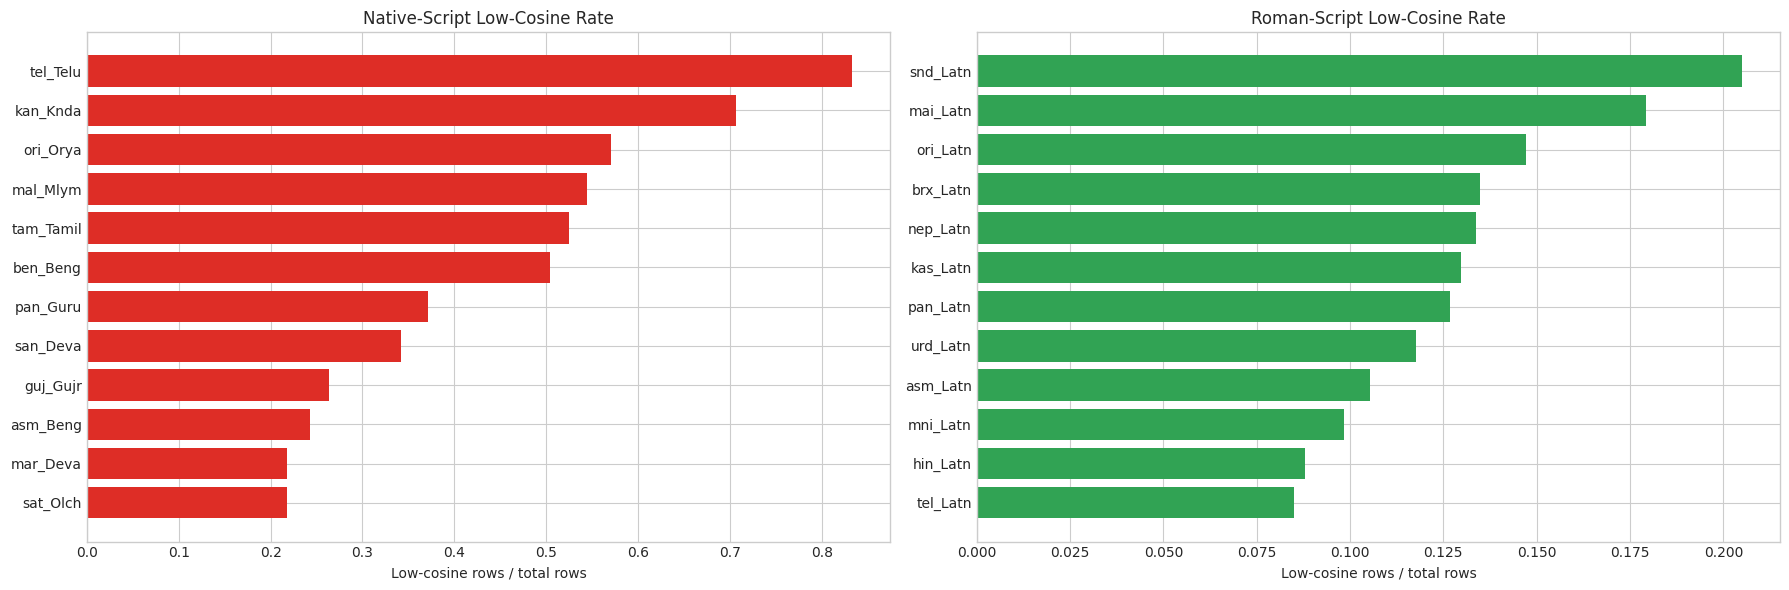

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(18, 6))

native_plot = native_lowcos_rates.query("total_rows >= 1000").head(12).sort_values("lowcos_rate")
axes[0].barh(native_plot["lid_lang"], native_plot["lowcos_rate"], color="#de2d26")
axes[0].set_title("Native-Script Low-Cosine Rate")
axes[0].set_xlabel("Low-cosine rows / total rows")

roman_plot = roman_lowcos_rates.query("total_rows >= 200").head(12).sort_values("lowcos_rate")
axes[1].barh(roman_plot["lid_lang"], roman_plot["lowcos_rate"], color="#31a354")
axes[1].set_title("Roman-Script Low-Cosine Rate")
axes[1].set_xlabel("Low-cosine rows / total rows")

plt.tight_layout()
plt.show()

In [11]:
display(Markdown("### Native low-cosine examples"))
display(pd.read_csv(FILES["native_lowcos"]).sort_values("cosine_before_after").head(12)[translated_cols])

display(Markdown("### Roman/Hinglish low-cosine examples"))
display(pd.read_csv(FILES["roman_lowcos"]).sort_values("cosine_before_after").head(12)[translated_cols])

### Native low-cosine examples

,row_id,lid_lang,nllb_src_lang,tweet_original,tweet,en_text,cosine_before_after
293487,5151545,tel_Telu,tel_Telu,"సినీ హీరోలతో పోటీపడుతూ చాలా అద్భుతంగా నటించే వారాయన. ఏ పాత్ర ఇచ్చినా ఆ పాత్రలో నటించి, అద్భుతమైన పేరు తెచ్చుకున్న వ్యక్తి. నేను కొంతకాలం వారితో కలిసి పనిచేయడం జరిగింది. ఆ కాలంలో వారితో కొన్ని అనుభవాలను కూడా పంచుకున్నాం. తెలుగు చలనచిత్ర పరిశ్రమ కైకాల గారిని కోల్పోవడం బాధాకరం: సీఎం","సినీ హీరోలతో పోటీపడుతూ చాలా అద్భుతంగా నటించే వారాయన. ఏ పాత్ర ఇచ్చినా ఆ పాత్రలో నటించి, అద్భుతమైన పేరు తెచ్చుకున్న వ్యక్తి. నేను కొంతకాలం వారితో కలిసి పనిచేయడం జరిగింది. ఆ కాలంలో వారితో కొన్ని అనుభవాలను కూడా పంచుకున్నాం. తెలుగు చలనచిత్ర పరిశ్రమ కైకాల గారిని కోల్పోవడం బాధాకరం: సీఎం",He was a very talented actor who competed with film heroes. He was a great actor who made a name for himself in any role. I worked with him for some time. We also shared some experiences with him during that time.,-0.1509
299009,5220147,tel_Telu,tel_Telu,"సినీ హీరోలతో పోటీపడుతూ చాలా అద్భుతంగా నటించే వారాయన. ఏ పాత్ర ఇచ్చినా ఆ పాత్రలో నటించి, అద్భుతమైన పేరు తెచ్చుకున్న వ్యక్తి. నేను కొంతకాలం వారితో కలిసి పనిచేయడం జరిగింది. ఆ కాలంలో వారితో కొన్ని అనుభవాలను కూడా పంచుకున్నాం. తెలుగు చలనచిత్ర పరిశ్రమ కైకాల గారిని కోల్పోవడం బాధాకరం: సీఎం","సినీ హీరోలతో పోటీపడుతూ చాలా అద్భుతంగా నటించే వారాయన. ఏ పాత్ర ఇచ్చినా ఆ పాత్రలో నటించి, అద్భుతమైన పేరు తెచ్చుకున్న వ్యక్తి. నేను కొంతకాలం వారితో కలిసి పనిచేయడం జరిగింది. ఆ కాలంలో వారితో కొన్ని అనుభవాలను కూడా పంచుకున్నాం. తెలుగు చలనచిత్ర పరిశ్రమ కైకాల గారిని కోల్పోవడం బాధాకరం: సీఎం",He was a very talented actor who competed with film heroes. He was a great actor who made a name for himself in any role. I worked with him for some time. We also shared some experiences with him during that time.,-0.1509
248376,4358326,tel_Telu,tel_Telu,"గతంలో మాదిరిగానే కనీస మద్దతు ధర చెల్లించి, రాష్ట్ర ప్రభుత్వమే ధాన్యం కొనుగోలు చేస్తుంది కనుక రాష్ట్రంలోని రైతులెవరూ తక్కువ ధరకు ధాన్యం ఇతరులకు అమ్మి, నష్టపోవద్దని ముఖ్యమంత్రి సూచించారు.","గతంలో మాదిరిగానే కనీస మద్దతు ధర చెల్లించి, రాష్ట్ర ప్రభుత్వమే ధాన్యం కొనుగోలు చేస్తుంది కనుక రాష్ట్రంలోని రైతులెవరూ తక్కువ ధరకు ధాన్యం ఇతరులకు అమ్మి, నష్టపోవద్దని ముఖ్యమంత్రి సూచించారు.","The Chief Minister suggested that no farmer in the state should sell the grain at a lower price to others, so that the state government would buy the grain at the same minimum support price as before.",-0.1497
298997,5220132,tel_Telu,tel_Telu,"ఇదే సూత్రాన్ని అనుసరించి సమస్త రంగాల్లో వృద్ధిరేటు వూహించని రీతిలో నమోదవుతూ, అటు తలసరి ఆదాయం, ఇటు జీఎస్డీపీ పెరుగుదలకు దోహదం చేసిందని సీఎం అన్నారు.","ఇదే సూత్రాన్ని అనుసరించి సమస్త రంగాల్లో వృద్ధిరేటు వూహించని రీతిలో నమోదవుతూ, అటు తలసరి ఆదాయం, ఇటు జీఎస్డీపీ పెరుగుదలకు దోహదం చేసిందని సీఎం అన్నారు.","Following the same principle, the growth rate in all sectors has been unpredictable, and this has contributed to the growth of Gross Domestic Product (GDP) and Gross Domestic Product (GDP).",-0.1315
362045,6267270,tam_Tamil,tam_Tamil,”எம்எல்ஏக்களுக்கு ஐபிஎல் பாஸ் - எஸ்பி வேலுமணி கோரிக்கை”\n\nhttps://t.co/WciCN2SQmv | #SPVelumani | #IPL | #News7Tamil | #News7TamilUpdates | #UdhayanidhiStalin | #TNAssembly https://t.co/y2pGrk4BMY,”எம்எல்ஏக்களுக்கு ஐபிஎல் பாஸ் - எஸ்பி வேலுமணி கோரிக்கை”\n\nhttps://t.co/WciCN2SQmv | #SPVelumani | #IPL | #News7Tamil | #News7TamilUpdates | #UdhayanidhiStalin | #TNAssembly https://t.co/y2pGrk4BMY,I want to know what I want to do. I want to know what I want to do.,-0.1313
65130,1249495,asm_Beng,asm_Beng,गोलमाल 😂 https://t.co/V3uSAvxFiv,गोलमाल 😂 https://t.co/V3uSAvxFiv,"The first is the ""Fireflowers"".",-0.1113
162494,2951837,tam_Tamil,tam_Tamil,(15.01.2021) விறு விறு செய்திகள் | Tamil Nadu | Thanthi TV \n\n#SpeedNews #TamilNadu \n\nhttps://t.co/v4HPxV1q22,(15.01.2021) விறு விறு செய்திகள் | Tamil Nadu | Thanthi TV \n\n#SpeedNews #TamilNadu \n\nhttps://t.co/v4HPxV1q22,This is the first time that a person has ever been in a situation where he is not able to get a job.,-0.1087
336224,5903238,tam_Tamil,tam_Tamil,அதிமுக வெளிநடப்பு - விளக்கம் \n\nhttps://t.co/WciCN2AH8n | #TNAssembly 

### Roman/Hinglish low-cosine examples

,row_id,lid_lang,nllb_src_lang,tweet_original,tweet,en_text,cosine_before_after
2012,3815528,kok_Latn,hin_Deva,Goa ❤️ @ArvindKejriwal https://t.co/4Qltj6UUC4,जीओए ❤️ @ArvindKejriwal https://t.co/4Qltj6UUC4,"The first is the ""Goldilocks"".",-0.1150
2975,6531389,san_Latn,hin_Deva,@UmarPat87072613 @shakilpatel86 @OICatUN @LadyVelvet_HFQ @HamdanMohammed @AllahGreatQuran @KingSalman @AliyaAbbas @alkawari4unesco @s_szama @aajtak @ABPNews @DibluKaka @DHOLUKHA8 @BBCHindi @AtmaramSoni3 @AnsariK786 @AnoopMaheshwar5 @AdarshK22237787 @Aafiya_khan_786 @Aam_Nagrik2315 @_MS_Ali_Rana @aapsur @alarafatengr @ALLAUDIENKHAN1 @Stanalb @ZulekhaJehan @MdtajKohri5 @Mansoor19302780 @Zaki_Sohail_INC @ExHindu07006862 @kf07b @Dhanpal85554293 @DevkarnMeenaINC @Deol123456788 @DeccanEnglish @DAS89764172 @CRUZONTIVEROS11 @creterion @BisnoiRamkaran @tanab786 Walekum Assalam,@UmarPat87072613 @shakilpatel86 @OICatUN @LadyVelvet_HFQ @HamdanMohammed @AllahGreatQuran @KingSalman @AliyaAbbas @alkawari4unesco @s_szama @aajtak @ABPNews @DibluKaka @DHOLUKHA8 @BBCHindi @AtmaramSoni3 @AnsariK786 @AnoopMaheshwar5 @AdarshK22237787 @Aafiya_khan_786 @Aam_Nagrik2315 @_MS_Ali_Rana @aapsur @alarafatengr @ALLAUDIENKHAN1 @Stanalb @ZulekhaJehan @MdtajKohri5 @Mansoor19302780 @Zaki_Sohail_INC @ExHindu07006862 @kf07b @Dhanpal85554293 @DevkarnMeenaINC @Deol123456788 @DeccanEnglish @DAS89764172 @CRUZONTIVEROS11 @creterion @BisnoiRamkaran @tanab786 वालेकुम अस्सलम,The first is the fact that the government has not yet made a decision on the issue of the issue of the right to vote. The first is that the government has not yet made a decision on the issue of the right to vote.,-0.1044
2478,4947961,kas_Latn,hin_Deva,@ParveenKader @sursmi @MehekF @kauserseema @p_iqbalkhan @s_szama @mazhar_jafri @INCAseemKP @asimtwitt @1Patelzuber @Lasani309 @tanveer1729 @INCObaid @Raheodisha @AwasimkKhan Waleykum Assalam.,@ParveenKader @sursmi @MehekF @kauserseema @p_iqbalkhan @s_szama @mazhar_jafri @INCAseemKP @asimtwitt @1Patelzuber @Lasani309 @tanveer1729 @INCObaid @Raheodisha @AwasimkKhan वालेकुम अस्सलम.,The first is the fact that the country is not a part of the Union.,-0.1001
2598,5254466,tam_Latn,hin_Deva,@mkstalin @CMOTamilnadu @arivalayam @Udhaystalin @PrabhuChawla @manojksonthalia @ptrmadurai @KPonmudiMLA @TRBRajaa @KanimozhiDMK @evvelu @TThenarasu @KN_NEHRU @V_Senthilbalaji,@mkstalin @CMOTamilnadu @arivalayam @Udhaystalin @PrabhuChawla @manojksonthalia @ptrmadurai @KPonmudiMLA @TRBRajaa @KanimozhiDMK @evvelu @TThenarasu @KN_NEHRU @V_Senthilbalaji,The first is the fact that the government has not yet taken any action to stop the spread of the virus.,-0.0946
2846,6088435,tam_Latn,hin_Deva,@mkstalin @CMOTamilnadu @arivalayam @Udhaystalin @PrabhuChawla @manojksonthalia @ptrmadurai @KPonmudiMLA @TRBRajaa @KanimozhiDMK @evvelu @TThenarasu @KN_NEHRU @V_Senthilbalaji,@mkstalin @CMOTamilnadu @arivalayam @Udhaystalin @PrabhuChawla @manojksonthalia @ptrmadurai @KPonmudiMLA @TRBRajaa @KanimozhiDMK @evvelu @TThenarasu @KN_NEHRU @V_Senthilbalaji,The first is the fact that the government has not yet taken any action to stop the spread of the virus.,-0.0946
1855,3498868,mal_Latn,hin_Deva,https://t.co/0aXtnESVGz\n@dhananjay_munde,https://t.co/0aXtnESVGz\n@dhananjay_munde,"The first is the ""City of the Dead"".",-0.0804
700,1432917,kas_Latn,hin_Deva,#EidMubarak \n@MehekF @sursmi @gops33 @tshamsi88 @Saira_Haleem @IAm_Sanjaysri @salimdotcomrade @s_szama @rohanmintoo @RutvikSubhedar @_iamSA1 @_JayHind_ @IncSapphire @SarcasticRofl @Madhuism_ @cleviic @KaviSharma789 @jawaharshivkish @rachitseth https://t.co/96sVMOBFbP,#ईदमुबारक @MehekF @sursmi @gops33 @tshamsi88 @Saira_Haleem @IAm_Sanjaysri @salimdotcomrade @s_szama @rohanmintoo @RutvikSubhedar @_iamSA1 @_JayHind_ @IncSapphire @SarcasticRofl @Madhuism_ @cleviic @KaviSharma789 @jawaharshivkish @rachitseth https://t.co/96sVMOBFbP,The first is the fact that the government has not yet made a decision on the issue of the issue of the issue of the right to vote.,-0.0790
1503

## Translation Quality By Language

This cell scans the translated outputs and computes mean cosine by language. It is heavier than the routing-summary cells.

In [12]:
native_cos = cosine_language_stats(FILES["native_translated"], min_count=1000)
roman_cos = cosine_language_stats(FILES["roman_translated"], min_count=200)

display(Markdown("### Native-script average cosine by language"))
display(native_cos.head(20))

display(Markdown("### Roman/Hinglish average cosine by language"))
display(roman_cos.head(20))

### Native-script average cosine by language

,lid_lang,count,avg_cosine
0,hin_Deva,3005825,0.7780
1,mai_Deva,288015,0.7240
2,mar_Deva,285182,0.6856
3,brx_Deva,106101,0.8046
4,doi_Deva,104304,0.7599
5,kas_Deva,79085,0.8029
6,guj_Gujr,76015,0.6533
7,tam_Tamil,65605,0.5402
8,tel_Telu,16221,0.3765
9,nep_Deva,12572,0.7525


### Roman/Hinglish average cosine by language

,lid_lang,count,avg_cosine
0,kas_Latn,4806,0.7418
1,kok_Latn,4555,0.8342
2,mal_Latn,3452,0.7899
3,urd_Latn,2967,0.7014
4,hin_Latn,2954,0.7102
5,asm_Latn,2468,0.6902
6,san_Latn,1859,0.8484
7,brx_Latn,1232,0.6744
8,ben_Latn,1181,0.7241
9,pan_Latn,954,0.7205


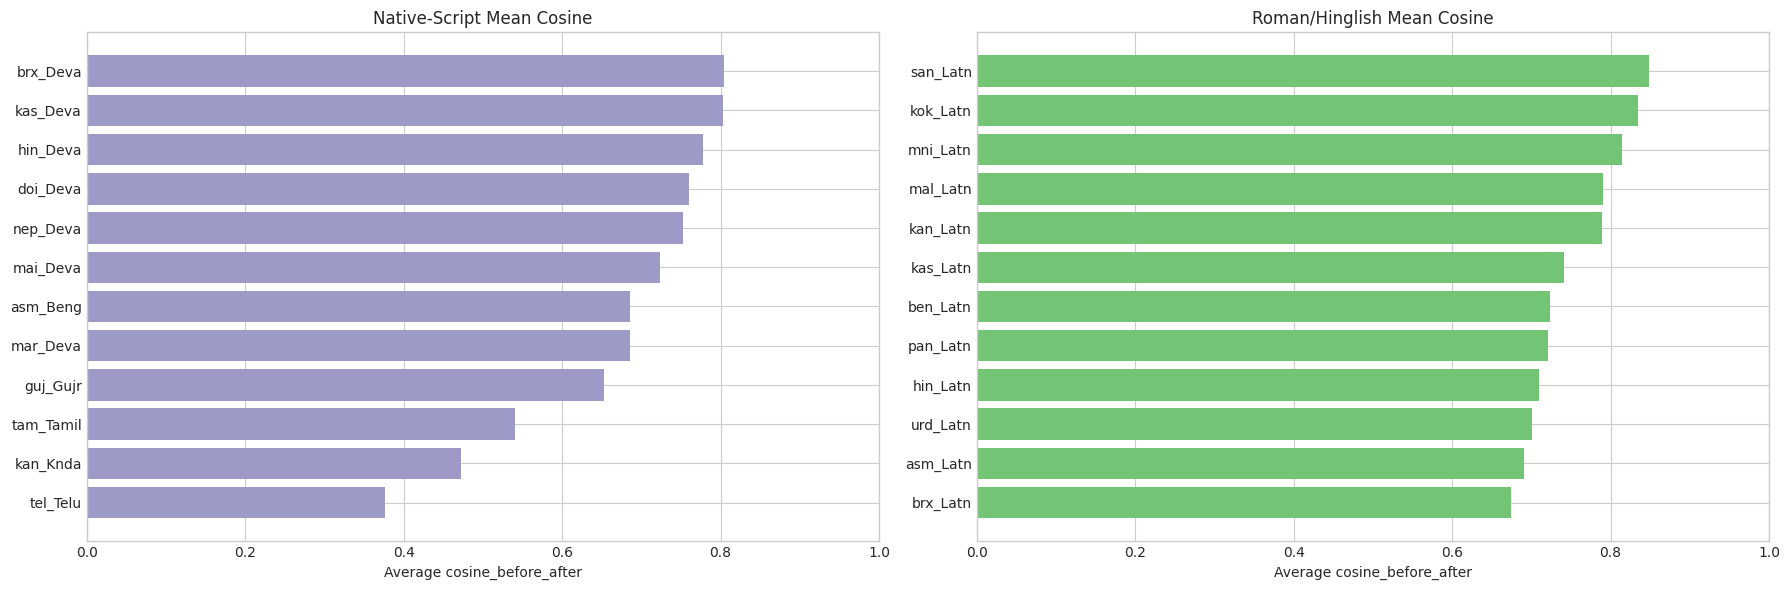

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(18, 6))

native_cos_plot = native_cos.head(12).sort_values("avg_cosine")
axes[0].barh(native_cos_plot["lid_lang"], native_cos_plot["avg_cosine"], color="#9e9ac8")
axes[0].set_xlim(0, 1)
axes[0].set_title("Native-Script Mean Cosine")
axes[0].set_xlabel("Average cosine_before_after")

roman_cos_plot = roman_cos.head(12).sort_values("avg_cosine")
axes[1].barh(roman_cos_plot["lid_lang"], roman_cos_plot["avg_cosine"], color="#74c476")
axes[1].set_xlim(0, 1)
axes[1].set_title("Roman/Hinglish Mean Cosine")
axes[1].set_xlabel("Average cosine_before_after")

plt.tight_layout()
plt.show()

## Final Output And Lookup Tools

Use these cells to inspect the merged English output or trace a specific `row_id` across stages.

In [14]:
merged_cols = ["row_id", "translation_route", "lid_lang", "tweet_original", "en_text", "translation_engine", "cosine_before_after"]

display(Markdown("### Final merged output sample"))
display(pd.read_csv(FILES["merged"], nrows=12, usecols=merged_cols))

display(Markdown("### Final merged route split"))
display(pd.read_csv(FILES["merged"], usecols=["translation_route"]).value_counts().rename("rows").reset_index())

### Final merged output sample

,row_id,tweet_original,translation_route,lid_lang,en_text,translation_engine,cosine_before_after
0,0,PM ⁦@narendramodi⁩ to launch Garib Kalyan Rojgar Abhiyaan on 20th June to boost livelihood opportunities in Rural India. \nhttps://t.co/zCG7yxUaGq\n\nvia NaMo App https://t.co/4i34NRHCYv,english,eng_Latn,PM ⁦@narendramodi⁩ to launch Garib Kalyan Rojgar Abhiyaan on 20th June to boost livelihood opportunities in Rural India. \nhttps://t.co/zCG7yxUaGq\n\nvia NaMo App https://t.co/4i34NRHCYv,unchanged,NaN
1,1,"A step towards economic resilience #aatmanirbharbharat, the FME scheme-with an outlay of 10,000 Crores shall seek to leverage investment worth 25000 Crore and generate gainful #employment for 9 lac people over the next 5 years.\n\nGet ready to script your food story. https://t.co/JC4Jk7xsLY",english,eng_Latn,"A step towards economic resilience #aatmanirbharbharat, the FME scheme-with an outlay of 10,000 Crores shall seek to leverage investment worth 25000 Crore and generate gainful #employment for 9 lac people over the next 5 years.\n\nGet ready to script your food story. https://t.co/JC4Jk7xsLY",unchanged,NaN
2,2,.@MOFPI_GOI wholeheartedly welcomes the Cabinet's decision on scheme for Formalisation of Micro food processing Enterprises (#FME) which shall provide a big boost to the SHGs/FPOs/Cooperatives &amp; micro food businesses and ensure adequate #livelihoods for rural-urban communities. https://t.co/2xOPJyjEQ0,english,eng_Latn,.@MOFPI_GOI wholeheartedly welcomes the Cabinet's decision on scheme for Formalisation of Micro food processing Enterprises (#FME) which shall provide a big boost to the SHGs/FPOs/Cooperatives &amp; micro food businesses and ensure adequate #livelihoods for rural-urban communities. https://t.co/2xOPJyjEQ0,unchanged,NaN
3,3,राज्यपाल भगतसिंह कोश्यारी यांनी मुख्यमंत्री उद्धव ठाकरे यांना पत्र लिहून विद्यापीठातील विद्यार्थ्यांच्या अंतिम वर्षाच्या परीक्षा घेण्यासंदर्भात महाराष्ट्र सार्वजनिक विद्यापीठ कायद्यातील तरतुदीनुसार निर्णय घेण्यात येईल असे कळविले आहे.,hindi_script,mar_Deva,Governor Bhagat Singh Koshyari has written to Chief Minister Uddhav Thakere to inform him that a decision will be taken in accordance with the provisions of the Maharashtra Public Universities Act regarding the final year examination of students of the university.,nllb,0.6582
4,4,VIDEO : Pune | केंद्रीय मंत्री प्रकाश जावडेकरांच्या घरासमोर शेतकऱ्यांचं आंदोलन\n#Pune #PrakashJavdekar #Farmer @PrakashJavdekar https://t.co/yIAmN8b2Ah,hindi_script,mar_Deva,VIDEO: Pune: Farmers' movement in front of the house of Union Minister Prakash Javadekar #Pune #PrakashJavdekar #Farmer @PrakashJavdekar https://t.co/yIAmN8b2Ah,nllb,0.9140
5,5,"'लडका छोटा हैं तो क्या हुआ?, बडा हमें ही करना हैं', सत्यजीत तांबेंसाठी अहमद पटेलांचा थेट ठाकरेंना फोन\nhttps://t.co/udNWWVywm8\n@satyajeettambe @INCMaharashtra #Congress",hindi_script,mar_Deva,"'What happened when the kids are small, the big ones we have to do', Ahmed Patel's direct call to Thakarena for Satyajit Tambeng https://t.co/udNWWVywm8 @satyajeettambe @INCMaharashtra #Congress",nllb,0.7620
6,6,पश्चिम बंगालच्या बीरभूममध्ये मंगळवारी राज्याच्या मुख्यमंत्री आणि तृणमूल काँग्रेसच्या प्रमुख ममता बनर्जी यांनी पदयात्रा काढली. यानंतर झालेल्या सभेत त्यांनी भाजप आणि पंतप्रधान मोदी यांच्यावर जोरदार हल्ला चढवला. https://t.co/BgkY81yDCo,hindi_script,mar_Deva,"The Chief Minister of the state of West Bengal and the head of the Trinamool Congress, Mamata Banerjee, marched to Birbhum, West Bengal.",nllb,0.3757
7,7,Russia agrees to produce coronavirus vaccine Sputnik V in India https://t.co/Xw8qbUU1Y1 https://t.co/6YTE5LQFsI,english,eng_Latn,Russia agrees to produce coronavirus vaccine Sputnik V in India https://t.co/Xw8qbUU1Y1 https://t.co/6YTE5LQFsI,unchanged,NaN
8,8,"Overwhelmed and deeply moved by everyone’s condolence messages through various channels.I’m sorry for not being able to respond immediately especially on whatsapp. I will do so slowly over time. Please pray for my papa. May Allah grant him jannat-e-fird

### Final merged route split

,translation_route,rows
0,hindi_script,4078560
1,english,3006222
2,hinglish_roman,31181


In [15]:
row_id_to_check = 166
row_hits = lookup_row(row_id_to_check)
for stage_name, df in row_hits.items():
    display(Markdown(f"### {stage_name}"))
    display(df)

/tmp/ipykernel_1815393/280187354.py:143: DtypeWarning: Columns (2,3,4,5,6) have mixed types. Specify dtype option on import or set low_memory=False.
  for chunk in pd.read_csv(path, chunksize=100_000):
/tmp/ipykernel_1815393/280187354.py:143: DtypeWarning: Columns (2,3,4,5,6) have mixed types. Specify dtype option on import or set low_memory=False.
  for chunk in pd.read_csv(path, chunksize=100_000):
/tmp/ipykernel_1815393/280187354.py:143: DtypeWarning: Columns (2,3,4,5,6) have mixed types. Specify dtype option on import or set low_memory=False.
  for chunk in pd.read_csv(path, chunksize=100_000):
/tmp/ipykernel_1815393/280187354.py:143: DtypeWarning: Columns (2,3,4,5,6) have mixed types. Specify dtype option on import or set low_memory=False.
  for chunk in pd.read_csv(path, chunksize=100_000):
/tmp/ipykernel_1815393/280187354.py:143: DtypeWarning: Columns (2,3,4,5,6) have mixed types. Specify dtype option on import or set low_memory=False.
  for chunk in pd.read_csv(path, chunksize=

### roman_routed

,timestamp,tweet,retweet_author,original_author,retweet_lc,original_lc,retweet_party,row_id,tweet_original,translation_route,lid_lang,lid_score,lid_model,xlit_lang,nllb_src_lang
0,2020-10-16 10:05:20+00:00,Oscar पुरस्कार से सम्मानित मशहूर कॉस्ट्यूम designer भानू अथैया जी का आज स्वर्गवास हुआ. सुनके मुझे बहुत दुख हुआ. गांधी film केई लिये उन्हे Oscar से सम्मानित किया गया था. उन्होंने हमारी Picture लेकिन केई लिये भी कॉस्ट्यूम डिजाइनिंग की थी. ईश्वर उनकी आत्मा को शांति de. https://t.co/JMB9a4o1n5,nlshmishra5,mangeshkarlata,nlshmishra5,mangeshkarlata,BJP,166,Oscar puraskar se sammanit mashhoor costume designer Bhanu Athaiya ji ka aaj swargwas hua. Sunke mujhe bahut dukh hua. Gandhi film ke liye unhe Oscar se sammanit kiya gaya tha. Unhone hamari Picture Lekin ke liye bhi costume Designing ki thi. Ishwar unki aatma ko shanti de. https://t.co/JMB9a4o1n5,hinglish_roman,hin_Latn,9.1028,IndicLID-BERT,hi,hin_Deva


### roman_translated

,timestamp,tweet,retweet_author,original_author,retweet_lc,original_lc,retweet_party,row_id,tweet_original,translation_route,lid_lang,lid_score,lid_model,xlit_lang,nllb_src_lang,devanagari_ratio,script,en_text,translation_engine,cosine_before_after
0,2020-10-16 10:05:20+00:00,Oscar पुरस्कार से सम्मानित मशहूर कॉस्ट्यूम designer भानू अथैया जी का आज स्वर्गवास हुआ. सुनके मुझे बहुत दुख हुआ. गांधी film केई लिये उन्हे Oscar से सम्मानित किया गया था. उन्होंने हमारी Picture लेकिन केई लिये भी कॉस्ट्यूम डिजाइनिंग की थी. ईश्वर उनकी आत्मा को शांति de. https://t.co/JMB9a4o1n5,nlshmishra5,mangeshkarlata,nlshmishra5,mangeshkarlata,BJP,166,Oscar puraskar se sammanit mashhoor costume designer Bhanu Athaiya ji ka aaj swargwas hua. Sunke mujhe bahut dukh hua. Gandhi film ke liye unhe Oscar se sammanit kiya gaya tha. Unhone hamari Picture Lekin ke liye bhi costume Designing ki thi. Ishwar unki aatma ko shanti de. https://t.co/JMB9a4o1n5,hinglish_roman,hin_Latn,9.1028,IndicLID-BERT,hi,hin_Deva,0.6345,devanagari,I was very sad to hear that the Oscar winning costume designer Bhanu Atayyaji was in heaven today. He was awarded the Oscar for Gandhi film. He designed costumes for our Picture but also for someone.,nllb,0.8130


### merged

,timestamp,tweet,retweet_author,original_author,retweet_lc,original_lc,retweet_party,row_id,tweet_original,translation_route,lid_lang,lid_score,lid_model,xlit_lang,nllb_src_lang,devanagari_ratio,script,en_text,translation_engine,cosine_before_after
0,2020-10-16 10:05:20+00:00,Oscar पुरस्कार से सम्मानित मशहूर कॉस्ट्यूम designer भानू अथैया जी का आज स्वर्गवास हुआ. सुनके मुझे बहुत दुख हुआ. गांधी film केई लिये उन्हे Oscar से सम्मानित किया गया था. उन्होंने हमारी Picture लेकिन केई लिये भी कॉस्ट्यूम डिजाइनिंग की थी. ईश्वर उनकी आत्मा को शांति de. https://t.co/JMB9a4o1n5,nlshmishra5,mangeshkarlata,nlshmishra5,mangeshkarlata,BJP,166,Oscar puraskar se sammanit mashhoor costume designer Bhanu Athaiya ji ka aaj swargwas hua. Sunke mujhe bahut dukh hua. Gandhi film ke liye unhe Oscar se sammanit kiya gaya tha. Unhone hamari Picture Lekin ke liye bhi costume Designing ki thi. Ishwar unki aatma ko shanti de. https://t.co/JMB9a4o1n5,hinglish_roman,hin_Latn,9.1028,IndicLID-BERT,hi,hin_Deva,0.6345,devanagari,I was very sad to hear that the Oscar winning costume designer Bhanu Atayyaji was in heaven today. He was awarded the Oscar for Gandhi film. He designed costumes for our Picture but also for someone.,nllb,0.8130


In [2]:
import pandas as pd
df = pd.read_csv("/scratch/ziv_baretto/Research_X/Partisan-Discourse-on-X-English-/Additional_Steps/Translating/Data/full_multilingual_en_20260403_detached/retweet_data_combined_labeled_by_retweet_en_with_hinglish_bridge.csv")
df.head()

/tmp/ipykernel_1786724/1527773751.py:2: DtypeWarning: Columns (2,3,4,5,6,13,14,16,20,21,22) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv("/scratch/ziv_baretto/Research_X/Partisan-Discourse-on-X-English-/Additional_Steps/Translating/Data/full_multilingual_en_20260403_detached/retweet_data_combined_labeled_by_retweet_en_with_hinglish_bridge.csv")


,timestamp,tweet,retweet_author,original_author,retweet_lc,original_lc,retweet_party,row_id,tweet_original,translation_route,...,xlit_lang,nllb_src_lang,devanagari_ratio,script,en_text,translation_engine,cosine_before_after,hinglish_roman_text,hinglish_hindi_text,hinglish_english_text
0,2020-06-18 11:59:57+00:00,PM ⁦@narendramodi⁩ to launch Garib Kalyan Rojg...,BJP4AnN,PMOIndia,bjp4ann,pmoindia,BJP,0,PM ⁦@narendramodi⁩ to launch Garib Kalyan Rojg...,english,...,NaN,NaN,NaN,NaN,PM ⁦@narendramodi⁩ to launch Garib Kalyan Rojg...,unchanged,NaN,NaN,NaN,NaN
1,2020-05-20 18:15:42+00:00,A step towards economic resilience #aatmanirbh...,BJP4AnN,MOFPI_GOI,bjp4ann,mofpi_goi,BJP,1,A step towards economic resilience #aatmanirbh...,english,...,NaN,NaN,NaN,NaN,A step towards economic resilience #aatmanirbh...,unchanged,NaN,NaN,NaN,NaN
2,2020-05-20 18:14:57+00:00,.@MOFPI_GOI wholeheartedly welcomes the Cabine...,BJP4AnN,MOFPI_GOI,bjp4ann,mofpi_goi,BJP,2,.@MOFPI_GOI wholeheartedly welcomes the Cabine...,english,...,NaN,NaN,NaN,NaN,.@MOFPI_GOI wholeheartedly welcomes the Cabine...,unchanged,NaN,NaN,NaN,NaN
3,2020-06-02 15:58:00+00:00,राज्यपाल भगतसिंह कोश्यारी यांनी मुख्यमंत्री उद...,Nitinkalebjp,maha_governor,nitinkalebjp,maha_governor,BJP,3,राज्यपाल भगतसिंह कोश्यारी यांनी मुख्यमंत्री उद...,hindi_script,...,NaN,mar_Deva,0.88412,devanagari,Governor Bhagat Singh Koshyari has written to ...,nllb,0.658203,NaN,NaN,NaN
4,2020-12-15 09:47:14+00:00,VIDEO : Pune | केंद्रीय मंत्री प्रकाश जावडेकरा...,VartakKuldeep,TV9Marathi,vartakkuldeep,tv9marathi,INC,4,VIDEO : Pune | केंद्रीय मंत्री प्रकाश जावडेकरा...,hindi_script,...,NaN,mar_Deva,0.38000,roman_hindi,VIDEO: Pune: Farmers' movement in front of the...,nllb,0.914003,NaN,NaN,NaN
